### Gerando dados sequenciais: ###

In [2]:
import numpy as np 
import matplotlib.pyplot as plt 

In [10]:
# Série senoide
def gerar_senoide(n=500):
    x = np.linspace(0, 100, n) 
    y = np.sin(x)
    return y

serie = gerar_senoide()

# Preparo de janelas de entrada e saída 
def criar_janelas(serie, janela=20):
    X, y = [], []
    for i in range(len(serie) - janela):
        X.append(serie[i:i+janela])
        y.append(serie[i+janela])
    return np.array(X), np.array(y)

X, y = criar_janelas(serie, janela=20)
X = X[..., np.newaxis] # adicionar dimensão para LSTM/GRU 

### Treinamento com LSTM e GRU: ###

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense
from sklearn.model_selection import train_test_split 

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

def treinar_modelo(rede='LSTM'):
    modelo = Sequential()
    if rede == 'LSTM':
        modelo.add(LSTM(50, input_shape=(X.shape[1], 1)))
    elif rede == 'GRU':
        modelo.add(GRU(50, input_shape=(X.shape[1], 1)))
        modelo.add(Dense(1))
        modelo.compile(optimizer='adam', loss='mse')
        modelo.fit(X_train, y_train, epochs=20, verbose=0)
    return modelo

modelo_lstm = treinar_modelo('LSTM')
modelo_gru = treinar_modelo('GRU') 

c:\VIRTUALENVS\RPA\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


### Avaliação: ###

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step 
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step 


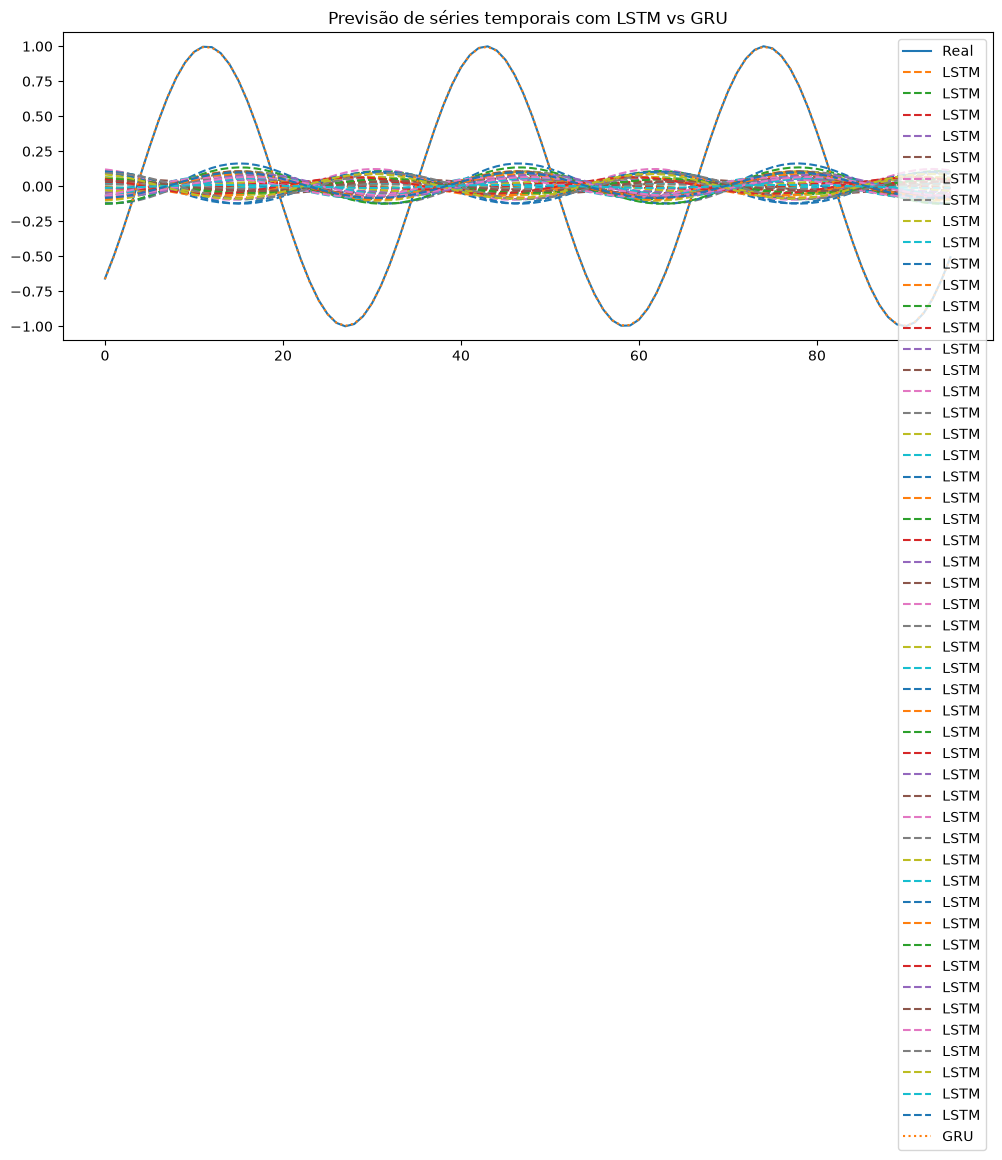

In [15]:
lstm_pred = modelo_lstm.predict(X_test)
gru_pred = modelo_gru.predict(X_test)

plt.figure(figsize=(12,4))
plt.plot(y_test, label='Real')
plt.plot(lstm_pred, label='LSTM', linestyle='--')
plt.plot(gru_pred, label='GRU', linestyle=':')
plt.title("Previsão de séries temporais com LSTM vs GRU")
plt.legend()
plt.show() 


### Parte 2 – Exemplo básico de GAN com geração de imagens (MNIST) ###
###  Gerador e Discriminador com keras: ###


In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, LeakyReLU, Flatten, Reshape
from tensorflow.keras.models import Sequential

def criar_gerador():
    modelo = Sequential([
        Dense(128, input_dim=100),
        LeakyReLU(0.2), 
        Dense(784, activation='tanh'),
        Reshape((28, 28))
    ])
    return modelo

def criar_discriminador():
    modelo = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(128),
        LeakyReLU(0.2),
        Dense(1, activation='sigmoid')
    ])
    return modelo

### Treinamento Adversarial: ###

In [18]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.datasets import mnist 

In [20]:
# Dados reais
(X_train, _), _ = mnist.load_data()

X_train = (X_train.astype(np.float32) - 127.5) /127.5 # normalização [-1,1] 

# Instâncias
gerador = criar_gerador()
discriminador = criar_discriminador()
discriminador.compile(loss='binary_crossentropy', optimizer=Adam(0.0002))

# GAN combinada
discriminador.trainable = False
gan = Sequential([gerador, discriminador])
gan.compile(loss='binary_crossentropy', optimizer=Adam(0.0002))


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


c:\VIRTUALENVS\RPA\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\VIRTUALENVS\RPA\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


### Loop de Treinamento (simplificado): ###

In [36]:
import os

def treinar_gan(epochs=1000, batch_size=128):
    for epoch in range(epochs):
        # Dados reais
        idx = np.random.randint(0, X_train.shape[0], batch_size)
        imgs_reais = X_train[idx] 

        # Dados falsos
        z = np.random.normal(0, 1, (batch_size, 100))
        imgs_falsas = gerador.predict(z)

        # Labels
        y_reais = np.ones((batch_size, 1))
        y_falsas = np.zeros((batch_size, 1))

        # Treinamento
        d_loss_real = discriminador.train_on_batch(imgs_reais, y_reais)
        d_loss_fake = discriminador.train_on_batch(imgs_falsas, y_falsas)

        # Gerador
        z = np.random.normal(0, 1, (batch_size, 100))
        g_loss = gan.train_on_batch(z, y_reais)

        if epoch % 200 == 0:
            print(f"Epoch {epoch}, D Loss: {d_loss_real + d_loss_fake}, G Loss: {g_loss}")
    treinar_gan(epochs=1000) 


### Visualizando imagens geradas: ###

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step


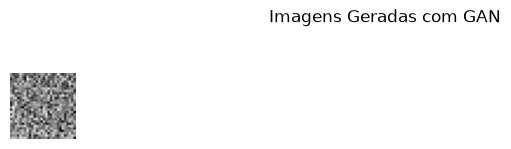

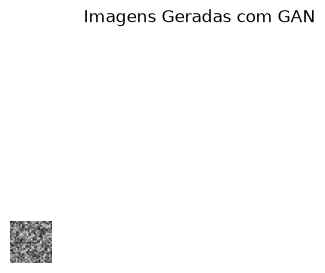

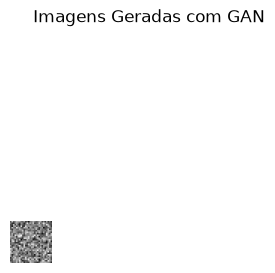

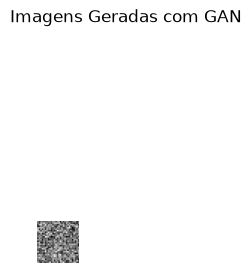

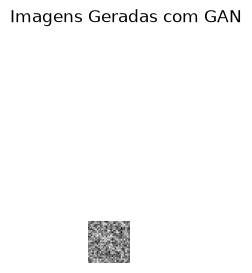

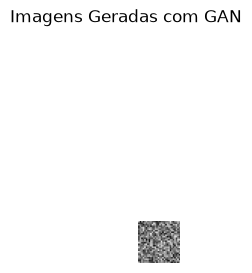

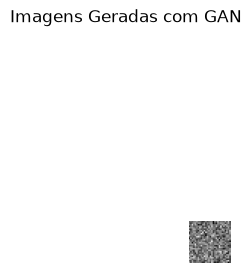

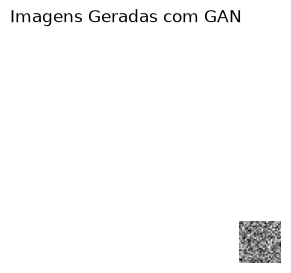

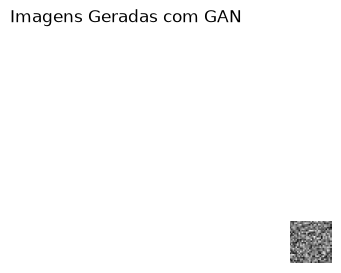

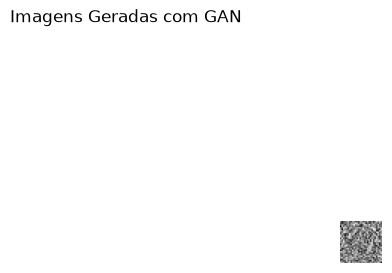

In [37]:
def gerar_imagens(n=10):
    noise = np.random.normal(0, 1, (n, 100))
    geradas = gerador.predict(noise)
    plt.figure(figsize=(10, 2))

    for i in range(n):
        plt.subplot(1, n, i+1)
        plt.imshow(geradas[i], cmap='gray')
        plt.axis('off')
        plt.suptitle("Imagens Geradas com GAN")
        plt.show()

gerar_imagens() 